# F3 : Prévision de l'inflation sous-jacente américaine à 12 mois (IPC hors alimentation et énergie, CPILFESL)

**Nom et prénom :Saber Sara     **Code Apogée :23009075    **Groupe :3    **Filière :** S7 FIN   **Date :** 17/11/2026

**Dépôt GitHub :** https:https://github.com/sabersaraaa/23009075-SABER-SARA-Fin3.git

## 1. Sujet et problématique
- **Intérêt du sujet** : L'inflation sous-jacente (hors alimentation et énergie) est moins volatile que l'inflation totale et sert de repère à la Réserve fédérale pour juger la tendance des prix. Une prévision à 12 mois intéresse les banques centrales (réglage du taux directeur), les entreprises (négociation des salaires et des contrats indexés) et les investisseurs obligataires (valorisation des titres indexés sur l'inflation, anticipation des taux).
- **Problématique** (une question) : L'historique de l'indice des prix sous-jacent (CPILFESL) suffit-il à prévoir l'inflation sous-jacente américaine 12 mois à l'avance, mieux que la simple persistance de l'inflation actuelle ?
- **Objectif mesurable** (fixé avant de voir les résultats de test) : RMSE de test du Ridge inférieure d'au moins 10 % à celle de la référence « dernière valeur », sur la période de test 2010-2025.
- **Nature du problème** : régression sur série temporelle, car la cible (inflation sous-jacente à t+12, en %) est un nombre réel et les observations sont ordonnées dans le temps, ce qui impose un découpage chronologique.
- **Algorithme principal envisagé** : n°2, Ridge. Choisi car les variables d'entrée (inflation et ses retards) sont fortement corrélées entre elles et que le Ridge reste stable dans ce cas, contrairement à une régression linéaire simple. Lasso et gradient boosting non retenus (voir section 5).

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# Configuration
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)

RAW = Path("data/raw");  RAW.mkdir(parents=True, exist_ok=True)
PROC = Path("data/processed"); PROC.mkdir(parents=True, exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


## 2. Jeu de données
**Source :** FRED (Federal Reserve Economic Data, Réserve fédérale de Saint-Louis), série `CPILFESL` : *Consumer Price Index for All Urban Consumers: All Items Less Food and Energy in U.S. City Average*, indice base 1982-1984 = 100, mensuel, désaisonnalisé. Origine primaire : Bureau of Labor Statistics (BLS). Lien : https://fred.stlouisfed.org/series/CPILFESL. Fichier `CPILFESL.xlsx` enregistré dans `data/raw/`.
**Date d'extraction :** 17/11/2026 (fichier créé par FRED le 2026-11-17 ; série mise à jour le 2026-11-10).
**Licence :** FRED indique que les données peuvent être soumises à droit d'auteur (voir https://fred.stlouisfed.org/legal#fred-terms-faq). Usage ici strictement pédagogique, avec citation de la source.

In [13]:
DATE_EXTRACTION = "2026-11-17"      # indiquée dans l'onglet README du fichier
chemin = RAW / "/content/drive/MyDrive/PARTIE B /CPILFESL.xlsx"

readme = pd.read_excel(chemin, sheet_name="README", header=None)
for ligne in readme.iloc[:, 0].dropna().astype(str):
    print(ligne)
print("-" * 60)
print(readme.iloc[7, 1], "|", readme.iloc[7, 2])
print("-" * 60)

brut = pd.read_excel(chemin, sheet_name="Monthly", index_col=0, parse_dates=True)
brut.index.name = "date"
brut["CPILFESL"] = pd.to_numeric(brut["CPILFESL"], errors="coerce")

print("Dimensions :", brut.shape)
print("Période :", brut.index.min().date(), "->", brut.index.max().date())
print("Fréquence estimée :", pd.infer_freq(brut.index))
print("Types :"); print(brut.dtypes)
display(brut.head())
display(brut.tail())

FRED Graph Observations
Federal Reserve Economic Data, Federal Reserve Bank of St. Louis
Link: https://fred.stlouisfed.org
Help: https://fredhelp.stlouisfed.org
This data may be copyrighted. Please refer to the Terms of Use: https://fred.stlouisfed.org/legal#fred-terms-faq
File Created: 2026-11-17 4:23 am CST
CPILFESL
------------------------------------------------------------
Consumer Price Index for All Urban Consumers: All Items Less Food and Energy in U.S. City Average, Index 1982-1984=100, Monthly, Seasonally Adjusted | Data Updated: 2026-11-10
------------------------------------------------------------
Dimensions : (838, 1)
Période : 1957-01-01 -> 2026-10-01
Fréquence estimée : MS
Types :
CPILFESL    float64
dtype: object


,CPILFESL
date,
1957-01-01,28.5
1957-02-01,28.6
1957-03-01,28.7
1957-04-01,28.8
1957-05-01,28.8


,CPILFESL
date,
2026-06-01,336.065
2026-07-01,336.789
2026-08-01,337.765
2026-09-01,338.896
2026-10-01,339.900


**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| CPILFESL | IPC hors alimentation et énergie | numérique | indice (1982-84 = 100) | brute (sert à calculer toutes les autres) | 0,12 (1 mois sur 838) |
| infl | 100 × (IPC_t / IPC_{t-12} − 1) : inflation sous-jacente sur 12 mois | numérique | % | explicative | créée |
| infl_ret3, infl_ret6, infl_ret12 | infl décalée de 3, 6 et 12 mois (`shift(k)`) | numérique | % | explicative | créée |
| mom_1m_ann, mom_3m_ann, mom_6m_ann | croissance de l'IPC sur 1, 3 et 6 mois, annualisée : 100 × ((IPC_t / IPC_{t-k})^(12/k) − 1) | numérique | % | explicative | créée |
| infl_moy36 | moyenne de infl sur les 36 derniers mois (niveau de long terme) | numérique | % | explicative | créée |
| infl_d12 | infl_t − infl_{t-12} (accélération sur un an) | numérique | points de % | explicative | créée |
| vol12 | écart-type sur 12 mois de la variation mensuelle de l'IPC | numérique | points de % | explicative | créée |
| cible | infl à la date t+12 (`shift(-12)`) | numérique | % | **cible** | créée |

**Unité d'observation :** un mois (une ligne = un mois, 838 observations de janvier 1957 à octobre 2026). **Variable cible :** inflation sous-jacente sur 12 mois, observée 12 mois après la date de prévision.
**Adéquation :** la série couvre près de 70 ans et plusieurs régimes d'inflation (années 1970, désinflation, période calme, choc de 2021-2022), ce qui permet un vrai test hors échantillon. Elle est la mesure officielle de l'inflation sous-jacente et on peut en tirer la cible (inflation à t+12) et des variables explicatives sans aucune autre source. Le jeu ne contient cependant que l'historique de l'indice : la question posée est donc bien « que vaut le passé de la série seul pour prévoir son avenir ? ».
**Limites :** **(1)** un mois manquant (octobre 2025) : le BLS n'a pas publié cet indice, probablement à cause de l'arrêt des services fédéraux américains à l'automne 2025 *(à vérifier sur le site du BLS)* ; **(2)** série désaisonnalisée et révisée après publication, donc valeurs d'aujourd'hui différentes de celles connues à l'époque (biais d'anticipation) ; **(3)** changements de régime (très forte inflation dans les années 1970 à 1980, puis 2 % environ, puis choc 2021-2022) ; **(4)** une seule série : aucune information sur le chômage, les taux ou les anticipations ; **(5)** observations mensuelles dont les cibles à 12 mois se chevauchent, ce qui réduit le nombre d'informations réellement indépendantes.

In [14]:
# Qualité : valeurs manquantes, doublons, régularité de l'index
manq = pd.DataFrame({"début de série": [brut["CPILFESL"].first_valid_index().date()],
                     "fin de série": [brut["CPILFESL"].last_valid_index().date()],
                     "manquants": [int(brut["CPILFESL"].isna().sum())],
                     "manquants (%)": [round(100 * brut["CPILFESL"].isna().mean(), 2)]}, index=["CPILFESL"])
display(manq)
print("Mois manquant(s) :", [x.date().isoformat() for x in brut.index[brut["CPILFESL"].isna()]])
print("Doublons d'index :", brut.index.duplicated().sum())
mois_attendus = pd.date_range(brut.index.min(), brut.index.max(), freq="MS")
print("Mois absents du calendrier :", len(mois_attendus.difference(brut.index)))
print("Valeurs <= 0 :", int((brut["CPILFESL"] <= 0).sum()))

# Interpolation linéaire des trous isolés (2 mois consécutifs au plus), sans combler le début ni la fin
df = brut.interpolate(limit=2, limit_area="inside")
print("Manquants après interpolation :", int(df["CPILFESL"].isna().sum()))
print(df.loc["2025-08":"2025-12"])
df.index.freq = "MS"

,début de série,fin de série,manquants,manquants (%)
CPILFESL,1957-01-01,2026-10-01,1,0.12


Mois manquant(s) : ['2025-10-01']
Doublons d'index : 0
Mois absents du calendrier : 0
Valeurs <= 0 : 0
Manquants après interpolation : 0
            CPILFESL
date                
2025-08-01  329.7000
2025-09-01  330.4180
2025-10-01  330.7305
2025-11-01  331.0430
2025-12-01  331.8140


**Qualité des données :** un seul mois manque, **octobre 2025** (0,12 % de la série), détecté avec `isna()` et par comparaison avec le calendrier mensuel complet. Décision : interpolation linéaire entre septembre et novembre 2025 (valeur obtenue : 330,73), car un seul mois est concerné et la série évolue lentement. Aucun doublon, aucune valeur négative ou nulle. Cette valeur reconstituée n'est pas une donnée officielle : elle influence les variables calculées sur 12 mois autour d'octobre 2025 et d'octobre 2026, ce qui est signalé dans l'analyse critique.

## 3. Exploration

In [15]:
df["infl"] = 100 * (df["CPILFESL"] / df["CPILFESL"].shift(12) - 1)
df["var_mens"] = 100 * df["CPILFESL"].pct_change()
display(df[["CPILFESL", "infl", "var_mens"]].describe().round(2))
print("Variation mensuelle négative :", int((df["var_mens"] < 0).sum()), "mois")

,CPILFESL,infl,var_mens
count,838.00,826.00,837.00
mean,144.39,3.65,0.30
std,90.58,2.46,0.24
min,28.50,0.60,-0.49
25%,49.12,2.02,0.15
50%,144.45,2.77,0.25
75%,218.85,4.61,0.38
max,339.90,13.60,1.42


Variation mensuelle négative : 13 mois


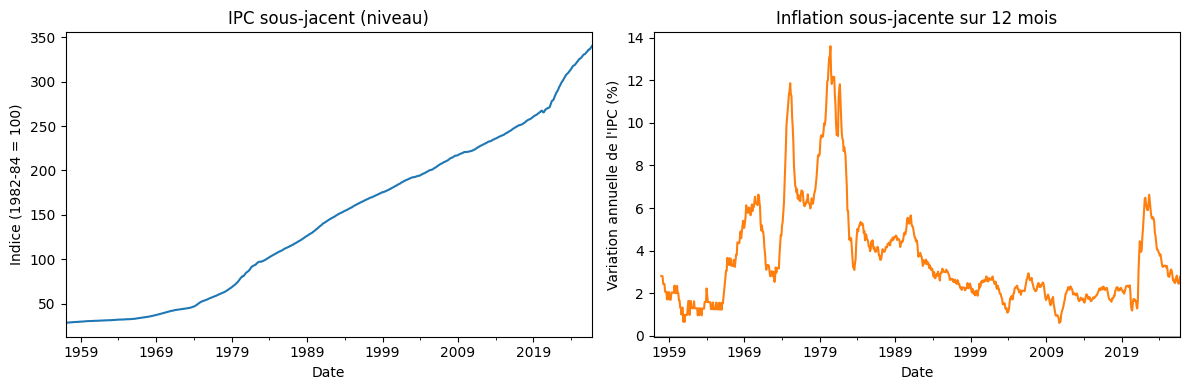

In [16]:
# Graphique 1 : niveau de l'indice et inflation sous-jacente
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
df["CPILFESL"].plot(ax=axs[0])
axs[0].set_title("IPC sous-jacent (niveau)"); axs[0].set_xlabel("Date"); axs[0].set_ylabel("Indice (1982-84 = 100)")
df["infl"].plot(ax=axs[1], color="tab:orange")
axs[1].axhline(0, color="grey", lw=0.5)
axs[1].set_title("Inflation sous-jacente sur 12 mois"); axs[1].set_xlabel("Date"); axs[1].set_ylabel("Variation annuelle de l'IPC (%)")
plt.tight_layout(); plt.savefig(FIG/"g1_inflation.png", dpi=150); plt.show()

**Interprétation du graphique 1 :** le niveau de l'indice croît de façon régulière et accélère dans les années 1970, mais c'est l'inflation sur 12 mois qui montre les régimes : un pic à 13,6 % vers 1980, une longue désinflation jusqu'aux années 1990, un niveau proche de 2 % pendant la période 2010-2019, puis un rebond à plus de 6 % en 2021-2022 avant un reflux vers environ 2,8 % fin 2026. La série n'est donc pas stationnaire en moyenne : une moyenne historique calculée sur le passé lointain sera un mauvais repère, ce qui justifie de la comparer à des références naïves plus adaptées.

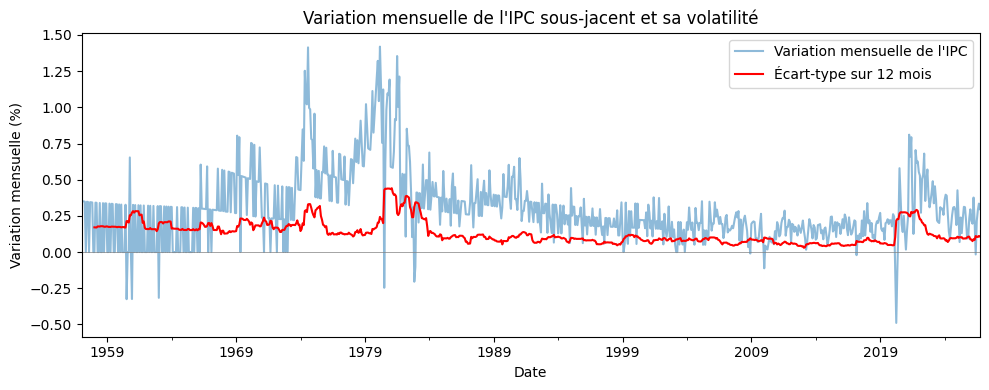

In [17]:
# Graphique 2 : variation mensuelle et volatilité glissante (régimes)
fig, ax = plt.subplots(figsize=(10, 4))
df["var_mens"].plot(ax=ax, alpha=0.5, label="Variation mensuelle de l'IPC")
df["var_mens"].rolling(12).std().plot(ax=ax, color="red", label="Écart-type sur 12 mois")
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Variation mensuelle de l'IPC sous-jacent et sa volatilité"); ax.set_xlabel("Date"); ax.set_ylabel("Variation mensuelle (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g2_volatilite.png", dpi=150); plt.show()

**Interprétation du graphique 2 :** la volatilité des variations mensuelles reste élevée jusqu'aux années 1980, baisse nettement à partir des années 1990 et reste faible pendant des décennies, puis remonte en 2020-2022. Les 13 mois de variation négative sont rares et dispersés (le plus marqué : avril 2020, −0,49 %). Conséquence pour la modélisation : l'écart-type des erreurs dépend de la période, et un modèle ajusté sur l'entraînement (qui inclut les années 1970) verra un test plus calme, sauf en 2021-2022.

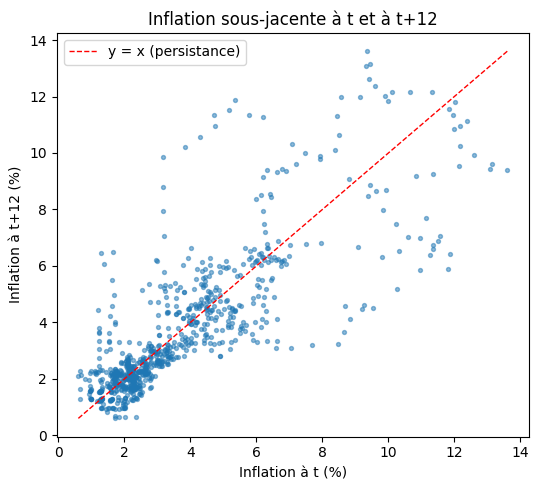

Corrélation infl_t / infl_t+12 : 0.812
Corrélation sur 2010 et après : 0.606


In [18]:
# Graphique 3 : inflation actuelle vs inflation 12 mois plus tard
tmp = pd.DataFrame({"infl_t": df["infl"], "infl_t12": df["infl"].shift(-12)}).dropna()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(tmp["infl_t"], tmp["infl_t12"], s=8, alpha=0.5)
lim = [tmp.min().min(), tmp.max().max()]
ax.plot(lim, lim, "r--", lw=1, label="y = x (persistance)")
ax.set_title("Inflation sous-jacente à t et à t+12"); ax.set_xlabel("Inflation à t (%)"); ax.set_ylabel("Inflation à t+12 (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g3_persistance.png", dpi=150); plt.show()
print("Corrélation infl_t / infl_t+12 :", round(tmp.corr().iloc[0, 1], 3))
print("Corrélation sur 2010 et après :", round(tmp.loc["2010":].corr().iloc[0, 1], 3))

**Interprétation du graphique 3 :** le nuage suit globalement la droite y = x (corrélation de 0,81 sur toute la série), donc l'inflation actuelle est un bon indicateur de l'inflation dans 12 mois et la référence « dernière valeur » est exigeante. La corrélation tombe à 0,61 depuis 2010, car l'inflation y varie peu et subit un choc isolé. On voit aussi que pour les valeurs élevées les points passent sous la droite : l'inflation forte a tendance à redescendre (retour vers la moyenne), un effet que la persistance pure ne capte pas.

**Qualité des données :** valeur manquante détectée (octobre 2025) et comblée par interpolation linéaire, décision et justification en section 2. Valeurs extrêmes (années 1970, début des années 1980, 2021-2022) **conservées** : ce sont des événements réels et ce sont justement eux que le modèle doit apprendre à traiter. Aucun doublon d'index, calendrier mensuel complet.

## 4. Préparation
Toutes les variables d'entrée utilisent uniquement l'information connue à la date t (retards avec `shift(k)`, k > 0, moyennes et écarts-types glissants calculés sur le passé et le présent). La cible est décalée vers le futur (`shift(-12)`), puis les lignes incomplètes sont retirées.

In [19]:
IPC = df["CPILFESL"]
for k in (3, 6, 12):
    df[f"infl_ret{k}"] = df["infl"].shift(k)
for k in (1, 3, 6):
    df[f"mom_{k}m_ann"] = 100 * ((IPC / IPC.shift(k)) ** (12 / k) - 1)
df["infl_moy36"] = df["infl"].rolling(36).mean()
df["infl_d12"] = df["infl"] - df["infl"].shift(12)
df["vol12"] = df["var_mens"].rolling(12).std()

df["cible"] = df["infl"].shift(-12)      # inflation sous-jacente à t+12

F_INFL  = ["infl", "infl_ret3", "infl_ret6", "infl_ret12"]
F_COURT = ["mom_1m_ann", "mom_3m_ann", "mom_6m_ann"]
F_LONG  = ["infl_moy36", "infl_d12", "vol12"]
TOUTES  = F_INFL + F_COURT + F_LONG

d = df.dropna(subset=TOUTES + ["cible"]).copy()
print("Observations utilisables :", len(d), "|", d.index.min().date(), "->", d.index.max().date())
# Preuve d'alignement : la cible d'une ligne est l'inflation 12 mois plus tard
display(d[["infl", "infl_ret12", "cible"]].head(3))
t0 = d.index[0]
print("Contrôle :", round(d.loc[t0, "cible"], 4), "==", round(df.loc[t0 + pd.DateOffset(months=12), "infl"], 4))
d.to_csv(PROC / "donnees_preparees.csv")

Observations utilisables : 779 | 1960-12-01 -> 2025-10-01


,infl,infl_ret12,cible
date,,,
1960-12-01,0.655738,2.006689,1.628664
1961-01-01,0.983607,2.006689,1.298701
1961-02-01,0.653595,2.341137,1.298701


Contrôle : 1.6287 == 1.6287


In [20]:
# Découpage chronologique : pas de mélange aléatoire.
# Entraînement : dernière date t = décembre 2008 (cible connue en décembre 2009).
# Les 12 mois de 2009 sont exclus pour que la cible de l'entraînement ne « regarde » pas le test.
train = d.loc[:"2008-12-01"]
test  = d.loc["2010-01-01":]
print(f"Entraînement : {len(train)} obs ({train.index.min().date()} -> {train.index.max().date()})")
print(f"Test         : {len(test)} obs ({test.index.min().date()} -> {test.index.max().date()})")

Entraînement : 577 obs (1960-12-01 -> 2008-12-01)
Test         : 190 obs (2010-01-01 -> 2025-10-01)


**Préparation :** la standardisation (`StandardScaler`) est incluse dans un `Pipeline` ; elle est donc ajustée sur l'entraînement seulement et réajustée dans chaque pli de validation croisée, ce qui évite toute fuite de données. Elle est nécessaire car le Ridge pénalise la taille des coefficients : des variables d'échelles différentes (inflation en %, volatilité en points) seraient pénalisées de façon inégale. Les variables n'utilisent que le passé (retards, moyennes glissantes), le test est strictement postérieur à l'entraînement et l'année 2009 est écartée pour que les cibles d'entraînement ne recouvrent pas le test.

## 5. Algorithme : régression Ridge (n°2)
**Intuition :** régression linéaire qui ajoute une pénalité sur la taille des coefficients, pour limiter le surapprentissage quand les variables sont corrélées (ici, l'inflation et ses retards décrivent la même série).

**Formule :**  min over β :  Σᵢ (yᵢ − β₀ − Σⱼ βⱼ xᵢⱼ)² + α Σⱼ βⱼ²

- yᵢ : inflation sous-jacente à 12 mois de l'observation i ; xᵢⱼ : valeur standardisée de la variable j ;
- β₀ : constante ; βⱼ : coefficient de la variable j (**appris**) ;
- α ≥ 0 : force de la pénalité (**hyperparamètre**, fixé par validation croisée). α = 0 redonne la régression linéaire ; α grand réduit les coefficients vers 0.

**Hyperparamètres :** `alpha` (effet : biais ↑ et variance ↓ quand α ↑) ; `fit_intercept` (constante apprise ou non). **Pourquoi pas une autre méthode :** le **Lasso** met à zéro certains coefficients, mais ici les retards d'une même série sont très corrélés : il en garderait un presque au hasard, alors que le Ridge répartit le poids entre eux de façon plus stable. Le **gradient boosting** (ou une forêt) pourrait capter des non-linéarités, mais avec 577 observations d'entraînement et des régimes très différents, il risque de surapprendre ; les arbres ne produisent aussi que des valeurs déjà vues à l'entraînement, ce qui est un défaut pour une série aux niveaux changeants. Le Ridge reste simple et interprétable.

## 6. Protocole expérimental
- **Découpage :** chronologique (voir section 4) ; validation croisée `TimeSeriesSplit` (5 plis, écart de 12 mois pour éviter le chevauchement des cibles).
- **Références naïves :** « dernière valeur » (inflation dans 12 mois = inflation actuelle) et « moyenne historique » de la cible sur l'entraînement.
- **Réglage :** `GridSearchCV` sur α (9 valeurs), sur l'entraînement uniquement.
- **Métrique principale :** RMSE (points de pourcentage d'inflation, pénalise les grosses erreurs). **Secondaires :** MAE (erreur moyenne en points) et R² (part de variance expliquée).
- **Test :** utilisé une seule fois, à la fin. **Configurations essayées :** 4 jeux de variables × 9 valeurs de α = 36.

In [21]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))

tscv = TimeSeriesSplit(n_splits=5, gap=12)
ALPHAS = np.logspace(-1, 3, 9)

def ajuster_ridge(cols):
    pipe = Pipeline([("sc", StandardScaler()), ("m", Ridge(random_state=GRAINE))])
    gs = GridSearchCV(pipe, {"m__alpha": ALPHAS}, cv=tscv,
                      scoring="neg_root_mean_squared_error", return_train_score=True)
    gs.fit(train[cols], train["cible"])
    i = gs.best_index_
    return gs, -gs.cv_results_["mean_test_score"][i], gs.cv_results_["std_test_score"][i]

# Références en validation croisée (mêmes plis)
s_pers, s_moy = [], []
for tr, va in tscv.split(train):
    s_pers.append(rmse(train["cible"].iloc[va], train["infl"].iloc[va]))
    s_moy.append(rmse(train["cible"].iloc[va], np.full(len(va), train["cible"].iloc[tr].mean())))

JEUX = {
    "Ridge, inflation seule":                 F_INFL,
    "Ridge, + dynamique récente":             F_INFL + F_COURT,
    "Ridge, + niveau de long terme":          F_INFL + F_LONG,
    "Ridge, toutes les variables":            TOUTES,
}
MODELES = {nom: ajuster_ridge(cols) for nom, cols in JEUX.items()}

cv_tab = pd.DataFrame(
    [["Référence (dernière valeur)", np.mean(s_pers), np.std(s_pers)],
     ["Référence (moyenne historique)", np.mean(s_moy), np.std(s_moy)]] +
    [[nom, m[1], m[2]] for nom, m in MODELES.items()],
    columns=["Modèle", "RMSE validation croisée (moyenne)", "Écart-type"]).round(2)
display(cv_tab)
for nom, m in MODELES.items():
    print(nom, "-> alpha =", round(m[0].best_params_["m__alpha"], 2))

,Modèle,RMSE validation croisée (moyenne),Écart-type
0,Référence (dernière valeur),1.40,1.06
1,Référence (moyenne historique),3.11,1.18
2,"Ridge, inflation seule",1.88,1.04
3,"Ridge, + dynamique récente",1.65,0.82
4,"Ridge, + niveau de long terme",1.90,0.80
5,"Ridge, toutes les variables",1.71,0.77


Ridge, inflation seule -> alpha = 100.0
Ridge, + dynamique récente -> alpha = 316.23
Ridge, + niveau de long terme -> alpha = 316.23
Ridge, toutes les variables -> alpha = 316.23


**Interprétation (validation croisée) :** en validation, la référence « dernière valeur » (RMSE 1,40) fait mieux que tous les Ridge (1,65 à 1,90) et bat nettement la moyenne historique (3,11). Les écarts-types (0,77 à 1,06) sont du même ordre que les écarts entre modèles : avec 5 plis très différents (années 1970, désinflation), on ne peut pas conclure à une différence nette. Parmi les Ridge, les variables de dynamique récente (momentum sur 1, 3 et 6 mois) apportent le plus (1,88 → 1,65). Le meilleur α (100 à 316) est à l'intérieur de la grille, pas à son bord. La validation ne confirme donc pas, à elle seule, l'avantage du Ridge : le résultat du test est à lire avec prudence.

## 7. Résultats
Le jeu de test est utilisé ici pour la première fois.

In [22]:
PRINCIPAL = "Ridge, toutes les variables"
y_test = test["cible"]
lignes = []
for nom, m in MODELES.items():
    p = m[0].predict(test[JEUX[nom]])
    lignes.append([nom, rmse(y_test, p), mean_absolute_error(y_test, p), r2_score(y_test, p)])
p_pers = test["infl"]
p_moy = np.full(len(test), train["cible"].mean())
lignes.append(["Référence (dernière valeur)", rmse(y_test, p_pers), mean_absolute_error(y_test, p_pers), r2_score(y_test, p_pers)])
lignes.append(["Référence (moyenne historique)", rmse(y_test, p_moy), mean_absolute_error(y_test, p_moy), r2_score(y_test, p_moy)])
res = pd.DataFrame(lignes, columns=["Modèle", "RMSE test", "MAE test", "R² test"]).round(2)
display(res)

rm_ridge = res.loc[res["Modèle"] == PRINCIPAL, "RMSE test"].iloc[0]
rm_pers = res.loc[res["Modèle"] == "Référence (dernière valeur)", "RMSE test"].iloc[0]
ecart = (rm_ridge / rm_pers - 1) * 100
print(f"RMSE Ridge vs dernière valeur : {ecart:+.1f} %")
print("Objectif (-10 % par rapport à la référence) atteint ?", ecart <= -10)
res.to_csv(PROC / "resultats_test.csv", index=False)

,Modèle,RMSE test,MAE test,R² test
0,"Ridge, inflation seule",1.15,0.90,0.22
1,"Ridge, + dynamique récente",1.05,0.80,0.36
2,"Ridge, + niveau de long terme",1.11,0.89,0.28
3,"Ridge, toutes les variables",1.03,0.78,0.37
4,Référence (dernière valeur),1.20,0.78,0.16
5,Référence (moyenne historique),2.01,1.88,-1.35


RMSE Ridge vs dernière valeur : -14.2 %
Objectif (-10 % par rapport à la référence) atteint ? True


**Interprétation du tableau :** le Ridge avec toutes les variables atteint une RMSE de test de 1,03 contre 1,20 pour la dernière valeur, soit **−14,2 %** : **l'objectif de −10 % est atteint**. Le R² passe de 0,16 à 0,37, tandis que la moyenne historique est très mauvaise (R² = −1,35) car l'entraînement a une inflation moyenne de 4,2 % contre 2,7 % sur le test. Attention : la MAE est identique (0,78), donc le gain vient de la réduction des **grosses erreurs** (RMSE les pénalise) et non de l'erreur typique. Le jeu « dynamique récente » seul (1,05) fait presque aussi bien que le jeu complet (1,03) ; l'inflation seule donne 1,15, ce qui montre que le momentum à court terme est l'apport principal. Le R² positif reste modeste.

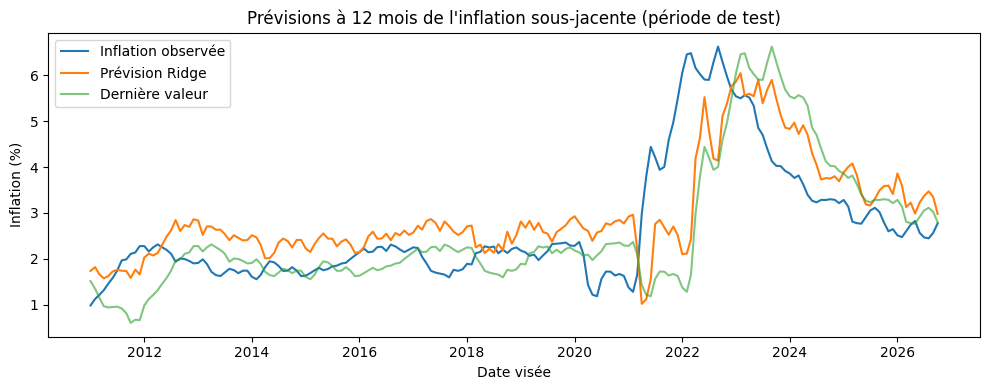

In [23]:
# Prévisions vs valeurs observées sur le test
p = MODELES[PRINCIPAL][0].predict(test[JEUX[PRINCIPAL]])
date_visee = test.index + pd.DateOffset(months=12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(date_visee, y_test.values, label="Inflation observée")
ax.plot(date_visee, p, label="Prévision Ridge")
ax.plot(date_visee, p_pers.values, label="Dernière valeur", alpha=0.6)
ax.set_title("Prévisions à 12 mois de l'inflation sous-jacente (période de test)"); ax.set_xlabel("Date visée"); ax.set_ylabel("Inflation (%)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g4_previsions.png", dpi=150); plt.show()

**Interprétation :** les trois courbes ratent le gros de la hausse de 2021-2022, ce qui est attendu : aucun modèle fondé sur le seul passé de l'indice ne l'anticipait. Le Ridge se distingue surtout après le pic : il redescend plus vite que la dernière valeur, qui reste en retard de 12 mois par construction, mais il demeure au-dessus de l'inflation observée en 2023-2024. En 2012-2019, il surestime l'inflation d'environ 0,5 point en moyenne (2,48 % prévu contre 1,98 % observé), car il est ajusté sur une période où l'inflation était plus haute.

,Période (date visée),Obs.,RMSE Ridge,RMSE dernière valeur
0,jusqu'à 2019,108,0.59,0.50
1,2020-2022,36,1.91,2.28
2,2023 et après,46,0.86,1.12


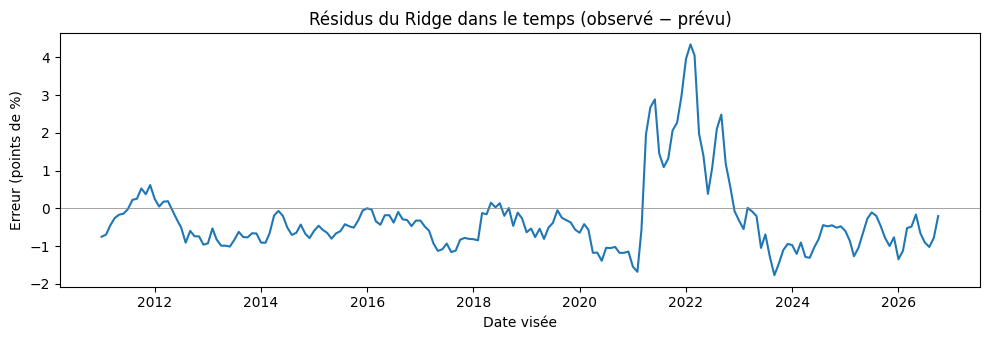

In [24]:
# Erreur selon la période (date visée)
err = pd.DataFrame({"y": y_test.values, "ridge": p, "pers": p_pers.values}, index=date_visee)
bornes = [("jusqu'à 2019", None, "2019-12-31"), ("2020-2022", "2020-01-01", "2022-12-31"), ("2023 et après", "2023-01-01", None)]
lignes = []
for nom, a, b in bornes:
    s = err.loc[a:b]
    lignes.append([nom, len(s), rmse(s["y"], s["ridge"]), rmse(s["y"], s["pers"])])
display(pd.DataFrame(lignes, columns=["Période (date visée)", "Obs.", "RMSE Ridge", "RMSE dernière valeur"]).round(2))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(err.index, err["y"] - err["ridge"])
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Résidus du Ridge dans le temps (observé − prévu)"); ax.set_xlabel("Date visée"); ax.set_ylabel("Erreur (points de %)")
plt.tight_layout(); plt.savefig(FIG/"g5_residus.png", dpi=150); plt.show()

**Analyse des erreurs :** par période, la dernière valeur fait **mieux jusqu'à 2019** (RMSE 0,50 contre 0,59) : dans un régime calme, la persistance est difficile à battre et le Ridge est tiré vers le haut par l'entraînement. Le Ridge gagne nettement en **2020-2022** (1,91 contre 2,28) et **à partir de 2023** (0,86 contre 1,12), c'est-à-dire quand l'inflation bouge. Les résidus sont négatifs et assez stables en 2012-2019, puis fortement positifs en 2021-2022 : le modèle sous-estime la poussée (erreur de +4,05 points pour la prévision de mars 2021), avant de redevenir négatifs. Le gain global dépend donc surtout d'un épisode, ce qui limite la portée de la conclusion.

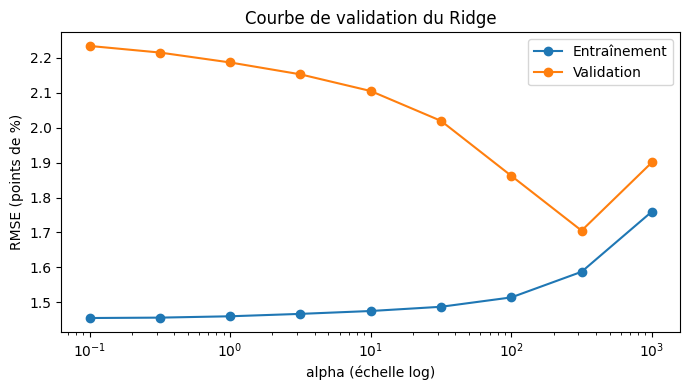

RMSE entraînement (ré-ajusté) : 1.48
RMSE validation croisée       : 1.71
RMSE test                     : 1.03


In [25]:
# Courbe de validation : RMSE selon alpha (modèle principal), pour discuter le surapprentissage
cv = MODELES[PRINCIPAL][0].cv_results_
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(ALPHAS, -cv["mean_train_score"], "o-", label="Entraînement")
ax.semilogx(ALPHAS, -cv["mean_test_score"], "o-", label="Validation")
ax.set_title("Courbe de validation du Ridge"); ax.set_xlabel("alpha (échelle log)"); ax.set_ylabel("RMSE (points de %)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG/"g6_validation.png", dpi=150); plt.show()
mod = MODELES[PRINCIPAL][0].best_estimator_
print("RMSE entraînement (ré-ajusté) :", round(rmse(train["cible"], mod.predict(train[JEUX[PRINCIPAL]])), 2))
print("RMSE validation croisée       :", round(MODELES[PRINCIPAL][1], 2))
print("RMSE test                     :", rm_ridge)

**Surapprentissage :** la courbe d'entraînement monte lentement avec α (1,46 → 1,76) tandis que la courbe de validation baisse de 2,23 à 1,71 avant de remonter à α = 1000 : un α faible ajuste trop finement le passé, un α très grand écrase trop les coefficients, et l'optimum se situe vers 316. Les erreurs sont de 1,48 sur l'entraînement, 1,71 en validation croisée et 1,03 sur le test. Le test est donc *plus faible* que l'entraînement : ce n'est pas du surapprentissage, mais un signe que la période de test est plus calme que celle de l'entraînement (années 1970-1980 incluses), et non une preuve de forte capacité de généralisation.

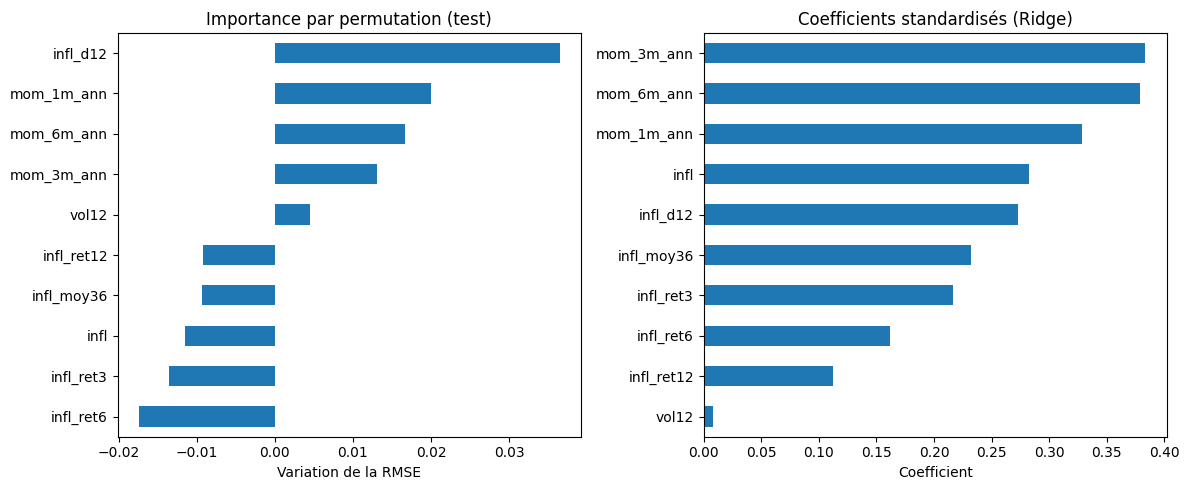

In [26]:
# Importance par permutation (jeu de test) et coefficients standardisés
cols = JEUX[PRINCIPAL]
pi = permutation_importance(mod, test[cols], y_test, n_repeats=20, random_state=GRAINE,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=cols).sort_values()
coef = pd.Series(mod.named_steps["m"].coef_, index=cols).sort_values()

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
imp.plot.barh(ax=axs[0]); axs[0].set_title("Importance par permutation (test)"); axs[0].set_xlabel("Variation de la RMSE")
coef.plot.barh(ax=axs[1]); axs[1].set_title("Coefficients standardisés (Ridge)"); axs[1].set_xlabel("Coefficient")
plt.tight_layout(); plt.savefig(FIG/"g7_importance.png", dpi=150); plt.show()

**Interprétation prudente :** tous les coefficients standardisés sont positifs (de 0,01 pour la volatilité à environ 0,38 pour le momentum sur 3 mois), mais ils sont corrélés entre eux et le Ridge répartit le poids entre variables proches. L'importance par permutation est très faible en valeur absolue (de l'ordre de 0,01 à 0,04 point de RMSE) : seules `infl_d12` (accélération sur un an) et les variables de momentum (1, 3 et 6 mois) dégradent nettement la RMSE quand on les mélange, tandis que les autres sont proches de zéro, voire légèrement négatives (bruit). Cela indique une information utile dans la dynamique récente, mais pas une relation de cause à effet.

In [27]:
# Illustration d'usage : 5 observations du test (non utilisées pour l'apprentissage)
dates = [x for x in ["2012-06-01", "2016-06-01", "2019-06-01", "2021-03-01", "2023-06-01"] if pd.Timestamp(x) in test.index]
ill = pd.DataFrame({
    "Date de prévision": dates,
    "Inflation actuelle (%)": [test.loc[x, "infl"] for x in dates],
    "Prévision Ridge à 12 mois (%)": mod.predict(test.loc[dates, cols]),
    "Valeur réelle à 12 mois (%)": [test.loc[x, "cible"] for x in dates],
}).round(2)
ill["Erreur (réel − prévu)"] = (ill["Valeur réelle à 12 mois (%)"] - ill["Prévision Ridge à 12 mois (%)"]).round(2)
display(ill)

,Date de prévision,Inflation actuelle (%),Prévision Ridge à 12 mois (%),Valeur réelle à 12 mois (%),Erreur (réel − prévu)
0,2012-06-01,2.19,2.64,1.62,-1.02
1,2016-06-01,2.26,2.78,1.70,-1.08
2,2019-06-01,2.07,2.57,1.18,-1.39
3,2021-03-01,1.65,2.43,6.48,4.05
4,2023-06-01,4.85,4.30,3.27,-1.03


**Commentaire :** pour les cinq dates, le Ridge prévoit entre 2,4 % et 4,3 %. En 2012, 2016 et 2019, il surestime d'environ 1 point (réel 1,2 à 1,7 %), cohérent avec le biais observé en période calme. En mars 2021, l'erreur est de +4,05 points : la prévision de 2,43 % rate totalement le saut à 6,48 % de mars 2022 (choc post-pandémie). En juin 2023, la prévision (4,30 %) est correcte en direction et surestime de 1,03 point la valeur réelle (3,27 %). Le modèle comprend donc le retour vers la moyenne mais pas les chocs soudains.

In [28]:
# Prévision pour les dernières données disponibles (modèle ré-entraîné sur toutes les cibles connues)
dernier = df.dropna(subset=cols).index[-1]
final = Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=MODELES[PRINCIPAL][0].best_params_["m__alpha"]))])
final.fit(d[cols], d["cible"])
prev = final.predict(df.loc[[dernier], cols])[0]
print(f"Dernière date complète : {dernier.date()} | inflation sous-jacente observée : {df.loc[dernier, 'infl']:.2f} %")
print(f"Prévision pour {(dernier + pd.DateOffset(months=12)).date()} : {prev:.2f} %  (ordre de grandeur d'incertitude : ± {rm_ridge:.2f} point, RMSE de test)")

Dernière date complète : 2026-10-01 | inflation sous-jacente observée : 2.77 %
Prévision pour 2027-10-01 : 3.20 %  (ordre de grandeur d'incertitude : ± 1.03 point, RMSE de test)


## 8. Analyse critique
- **Biais d'anticipation (look-ahead bias) :** CPILFESL est désaisonnalisée et révisée après publication ; les valeurs téléchargées aujourd'hui ne sont pas celles disponibles à l'époque. Les performances sont probablement optimistes. Piste : séries ALFRED (millésimes) ou série non désaisonnalisée.
- **Valeur reconstituée :** l'indice d'octobre 2025 est interpolé (non publié). Les variables calculées sur 12 mois autour d'octobre 2025 et d'octobre 2026 en dépendent, ainsi que la prévision finale ; l'effet est faible mais non nul.
- **Changements de régime :** l'entraînement mêle les années 1970-1980 (inflation très forte et volatile) et les décennies suivantes ; le modèle est tiré vers une moyenne d'entraînement de 4,2 % alors que l'inflation est ensuite plus basse, d'où le biais de 2012-2019. Piste : entraîner sur une fenêtre plus récente, ou introduire un indicateur de régime.
- **Un seul découpage :** une seule date de coupure (2010) et un test où les cibles à 12 mois se chevauchent. Le gain de 14 % repose largement sur 2020-2023 (voir section 7). Piste : tester d'autres dates de coupure (2000, 2015) et des fenêtres glissantes.
- **Validation et test discordants :** en validation croisée la dernière valeur reste meilleure (1,40 contre 1,65), alors que le test donne l'inverse. Le résultat n'est donc pas robuste.
- **Une seule série :** l'information se limite à l'historique de l'indice. Le chômage, les taux directeurs, les anticipations d'inflation et les prix de l'énergie n'y figurent pas. Piste : ajouter UNRATE, FEDFUNDS ou des anticipations (comme dans le sujet F3 complet).
- **Corrélation ≠ causalité :** l'importance des variables mesure leur usage par le modèle, pas un mécanisme économique.

## 9. Conclusion
L'historique de l'indice sous-jacent seul permet de prévoir l'inflation à 12 mois un peu mieux que la persistance sur la période de test : RMSE de 1,03 point pour le Ridge contre 1,20 pour la dernière valeur (−14,2 %), donc **l'objectif de −10 % est atteint** et le R² passe de 0,16 à 0,37. Ce résultat est toutefois fragile : l'erreur moyenne (MAE) est identique (0,78), la persistance fait mieux jusqu'à 2019 et en validation croisée, et le gain vient surtout de la période 2020-2023. Aucun modèle n'anticipe le choc de 2021-2022. Le Ridge est utile pour capter le retour vers la moyenne et le momentum à court terme, pas pour prévoir les ruptures. La prévision pour octobre 2027 est de **3,20 %**, avec une incertitude d'environ ± 1 point : à prendre comme un ordre de grandeur, non comme une certitude.

## 10. Références et reproduction
- FRED / BLS : CPILFESL, https://fred.stlouisfed.org/series/CPILFESL (date d'extraction : 17/11/2026, voir cellule de chargement).
- Support du cours `Tp_ML.ipynb` ; documentation scikit-learn.
- **Reproduction :** placer `CPILFESL.xlsx` dans `data/raw/`, `pip install -r requirements.txt`, puis « Redémarrer et tout exécuter ». Dépôt : ...

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| ... | ... | ... | ... | ... |